              datetime  season  holiday  workingday  weather  temp   atemp  \
0  2011-01-01 00:00:00       1        0           0        1  9.84  14.395   
1  2011-01-01 01:00:00       1        0           0        1  9.02  13.635   
2  2011-01-01 02:00:00       1        0           0        1  9.02  13.635   
3  2011-01-01 03:00:00       1        0           0        1  9.84  14.395   
4  2011-01-01 04:00:00       1        0           0        1  9.84  14.395   

   humidity  windspeed  casual  registered  count  hour  
0        81        0.0       3          13     16     0  
1        80        0.0       8          32     40     1  
2        80        0.0       5          27     32     2  
3        75        0.0       3          10     13     3  
4        75        0.0       0           1      1     4  
Index(['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp',
       'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count',
       'hour'],
      dtype='object'

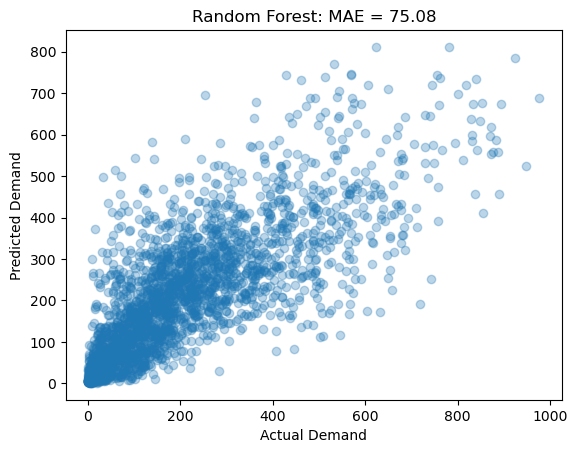

    feature  importance
0      hour    0.578465
1      temp    0.223361
2  humidity    0.159941
3   weather    0.038233


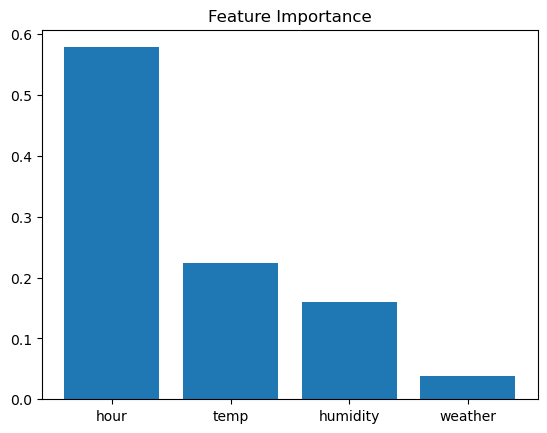

In [2]:
# Cell 1: Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Cell 2: Load data
df = pd.read_csv('train.csv')
df['hour'] = pd.to_datetime(df['datetime']).dt.hour
print(df.head())
print(df.columns)

# Cell 3: Feature selection
features = ['hour', 'temp', 'humidity', 'weather']
target = 'count'
X = df[features]
y = df[target]

# Cell 4: Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# Cell 5: Train model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Cell 6: Evaluate
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"MAE: {mae:.2f}, RMSE: {rmse:.2f}")

# Cell 7: Plot actual vs predicted
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title(f"Random Forest: MAE = {mae:.2f}")
plt.show()

# Cell 8: Feature importance
importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)
print(importance)
plt.bar(importance['feature'], importance['importance'])
plt.title("Feature Importance")
plt.show()